# **TD 1: Économétrie appliquée.**

###Lors de ce TD, on va faire une analyse du risque de marché de 5 actions européennes avec Python.

Nous allons notamment chercher à comprendre comment les actions réagissent aux variations du marché boursier, puis déterminer si cette relation est statistiquement significative. Enfin, nous examinerons la fiabilité de nos résultats, notamment lorsque les marchés financiers connaissent de fortes périodes de volatilité.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
%matplotlib inline

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.grid":True,
    "grid.alpha": 0.3
})

In [3]:
prix = pd.read_csv("/content/prix_actions.csv", index_col="date", parse_dates=True)

In [4]:
prix

,INDICE_EURO50,LUXE_SA,ENERGIE_SA,BANQUE_SA,PHARMA_SA,UTILITIES_SA
date,,,,,,
2015-01-01,4200.00,140.02,45.00,51.99,78.00,95.01
2015-01-02,4228.19,140.91,44.60,52.74,77.13,95.01
2015-01-05,4215.20,139.15,45.10,53.19,76.26,93.83
2015-01-06,4244.53,136.62,45.67,55.10,75.33,93.24
2015-01-07,4255.94,138.34,46.14,56.30,75.35,93.32
...,...,...,...,...,...,...
2026-06-24,7437.08,393.14,67.98,67.95,119.89,128.49
2026-06-25,7485.89,396.33,67.07,67.36,119.65,129.46
2026-06-26,7433.40,393.77,66.11,66.62,121.22,127.73


In [5]:
rdt = np.log(prix).diff().dropna() #Rendement logarithmiques.

In [6]:
titres = [c for c in prix.columns if c!= "INDICE_EURO50"] #Ici on sépare l'indice des actions pour la variable titres.

Nous allons commencer par construire un nuage de points pour BANQUE_SA, puis nous analyserons sa régression linéaire.

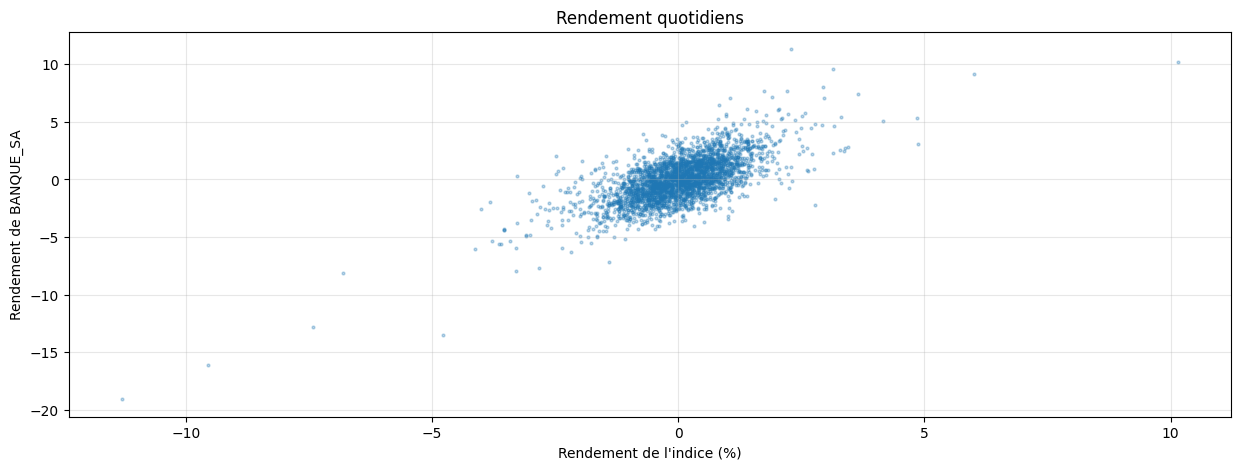

In [7]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.scatter(rdt["INDICE_EURO50"]*100, rdt["BANQUE_SA"]*100,
           s=4, alpha=0.3)
ax.set_xlabel("Rendement de l'indice (%)")
ax.set_ylabel("Rendement de BANQUE_SA")
ax.set_title("Rendement quotidiens")
plt.show()

In [8]:
modele = smf.ols("BANQUE_SA ~ INDICE_EURO50", data=rdt).fit()
#On cherche à expliquer les variations du rendement de BANQUE_SA (y) par les variations du rendement de INDICE_EURO50 (X).

In [9]:
print(modele.summary())

                            OLS Regression Results                            
Dep. Variable:              BANQUE_SA   R-squared:                       0.465
Model:                            OLS   Adj. R-squared:                  0.465
Method:                 Least Squares   F-statistic:                     2601.
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:05:32   Log-Likelihood:                 8451.8
No. Observations:                2998   AIC:                        -1.690e+04
Df Residuals:                    2996   BIC:                        -1.689e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -0.0002      0.000     -0.653

In [10]:
resume = pd.DataFrame({
    "coef": modele.params,
    "st. err": modele.bse,
    "t": modele.tvalues,
    "p-value": modele.pvalues
}) #Je crée un df pour avoir le coef, standard error, t de student et la pvalue de mon modèle.

In [11]:
resume = resume.join(modele.conf_int().set_axis(["IC 2.5%", "IC 97.5%"], axis=1))

In [12]:
resume

,coef,st. err,t,p-value,IC 2.5%,IC 97.5%
Intercept,-0.000172,0.000264,-0.653403,0.513546,-0.000690,0.000345
INDICE_EURO50,1.338735,0.026250,50.999789,0.000000,1.287265,1.390204


Mon beta estimé est bien dans mon IC. 0 n'est pas à cette intervalle donc le beta est significatif au seuil de 5%.

In [13]:
b = modele.params["INDICE_EURO50"] #beta
a = modele.params["Intercept"] #alpha

In [14]:
print(f"Beta: {b:.2f} ; quand l'indice augmente de 1%, la banque gagne en moyenne {b:.2f} %.")
print(f"Alpha annualisé: {a*252:.2%} (pvalue {modele.pvalues["Intercept"]:.2f})")
print(f"R squared: {modele.rsquared:.2f}; part du risque (systématique) du titre expliqué par le marché.")
print(f"Le reste ({1-modele.rsquared:.0%}) est du risque spécifique, diversifiable.")

Beta: 1.34 ; quand l'indice augmente de 1%, la banque gagne en moyenne 1.34 %.
Alpha annualisé: -4.34% (pvalue 0.51)
R squared: 0.46; part du risque (systématique) du titre expliqué par le marché.
Le reste (54%) est du risque spécifique, diversifiable.


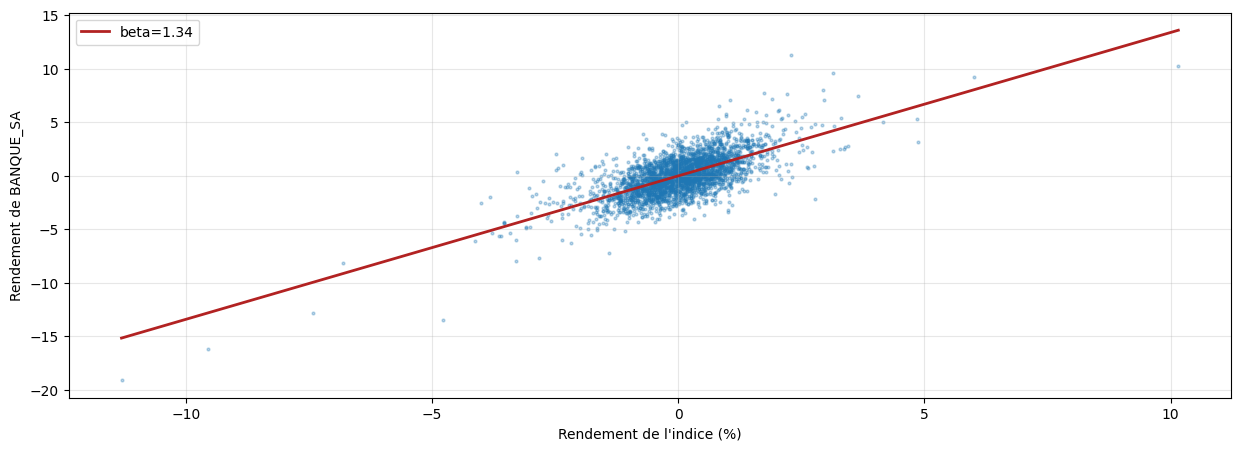

In [15]:
grille = np.linspace(rdt["INDICE_EURO50"].min(), rdt["INDICE_EURO50"].max(), 2)

fig, ax = plt.subplots(figsize=(15, 5))
ax.scatter(rdt["INDICE_EURO50"]*100, rdt["BANQUE_SA"]*100, s=4, alpha=0.3)
ax.plot(grille * 100, (a + b * grille) * 100, color="firebrick", lw=2, label=f"beta={b:.2f}")

ax.set_xlabel("Rendement de l'indice (%)")
ax.set_ylabel("Rendement de BANQUE_SA")
ax.legend()
plt.show()

Maintenant nous allons compléter avec les autres titres.

In [16]:
lignes = {}

for titre in titres:
  m = smf.ols(f"{titre} ~ INDICE_EURO50", data=rdt).fit()
  lignes[titre] = {
      "beta": m.params["INDICE_EURO50"],
      "p_value": m.pvalues["INDICE_EURO50"],
      "t": m.tvalues["INDICE_EURO50"],
      "R2": m.rsquared
  }

betas = pd.DataFrame(lignes).T.sort_values("beta", ascending=False)

In [17]:
betas

,beta,p_value,t,R2
BANQUE_SA,1.338735,0.000000e+00,50.999789,0.464711
LUXE_SA,1.173206,0.000000e+00,44.131852,0.393966
ENERGIE_SA,0.947817,5.371433e-262,38.336637,0.329108
PHARMA_SA,0.577364,3.031567e-165,29.207895,0.221636
UTILITIES_SA,0.482042,2.638020e-150,27.673540,0.203578


Les 5 p-values sont inférieures à 0.05 donc on rejette H0 pour les 5 titres. Alors les betas sont significativements différents de 0.

Pour BANQUE_SA et LUXE_SA, les betas sont > 1 ce qui signifies que ce sont des titres cycliques, qui amplifient le marché.

Pour les autres titres, où les beta sont < 1, ce sont des titres défensifs qui amortissent le marché. Ils sont recherché en période de crise.

Le R squared montre la part des variations du titre expliquée par le marché. Plus il est élevé, plus le marché explique les variations du titre.

### On vérifie l'hypothèse d'Homoscédasticité avec les tests de Breusch Pagan et de White.

Rappel:


H0: Homocédasticité; H1: Hétéroscédasticité

*   Si p-value < 0.05, on rejette H0 = Hétéroscédasticité détectée.
*   Si non, la variance des erreurs est constante (Homocédasticité).


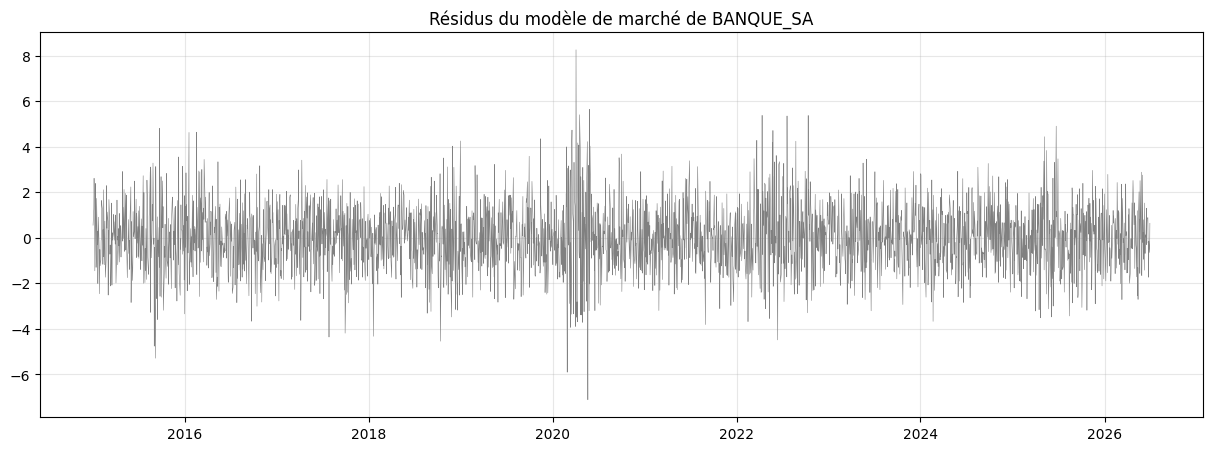

In [18]:
fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(modele.resid.index, modele.resid*100, lw=0.4, color="grey")
ax.set_title("Résidus du modèle de marché de BANQUE_SA")
plt.show()

Les résidus sont beaucoup plus dispersés pendant les crises: ils sont
hétéroscédastiques.

In [19]:
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

In [20]:
p_bp = het_breuschpagan(modele.resid, modele.model.exog)[1]

In [21]:
p_white = het_white(modele.resid, modele.model.exog)[1]

In [22]:
print(f"p-value BP: {p_bp:.3f} ; p-value White: {p_white:.3f}" )

p-value BP: 0.569 ; p-value White: 0.000


Pour le test de Breusch Pagan, 0.569 > 0.05 : on ne rejette pas H0 (variance des erreurs constantes).

Pour le test de White, on rejette H0, ce qui indique une présence d'hétéroscédasticité. La variance dépend de l'amplitude des mouvements du marché, indépendamment de leur signe. Nos t-statistiques et pvalues, peuvent être peu fiables.

 On va utiliser HC3 pour vérifier si nos conclusions restent fiables.

In [23]:
robuste = smf.ols("BANQUE_SA ~INDICE_EURO50", data=rdt).fit(cov_type="HC3")

In [24]:
pd.DataFrame({
    "coef": modele.params,
    "st err usuel": modele.bse,
    "st err robuste (HC3)": robuste.bse}).round(4)

,coef,st err usuel,st err robuste (HC3)
Intercept,-0.0002,0.0003,0.0003
INDICE_EURO50,1.3387,0.0262,0.0400


Le coefficient beta reste inchangé après l'application de la correction robuste HC3. En revanche, l'erreur standard augmente de 0.0262 à 0.0400. Cela montre que les erreurs standards classiques sous estimaient l'incertitude statistique autour du beta par rapport à la méthode robuste HC3. Malgré cette correction, le beta reste statistiquement significatif au seuil de 1%. La relation entre le rendement de BANQUE_SA et de l'indice INDICE_EURO50 reste donc significative.

Et les autres titres ?

In [25]:
lignes2 = {}

for titre in titres:
    m2 = smf.ols(f"{titre} ~ INDICE_EURO50", data=rdt).fit()

    p2_bp = het_breuschpagan(m2.resid, m2.model.exog)[1]
    p2_white = het_white(m2.resid, m2.model.exog)[1]

    lignes2[titre] = {
        "p_value BP": p2_bp,
        "p_value White": p2_white,
        "Test Breusch Pagan": "Rejet H0" if p2_bp < 0.05 else "On ne rejette pas H0",
        "Test White": "Rejet H0" if p2_white < 0.05 else "On ne rejette pas H0"
    }

resultats = pd.DataFrame(lignes2).T

In [26]:
resultats

,p_value BP,p_value White,Test Breusch Pagan,Test White
LUXE_SA,0.055452,0.0,On ne rejette pas H0,Rejet H0
ENERGIE_SA,0.320684,0.0,On ne rejette pas H0,Rejet H0
BANQUE_SA,0.568633,0.0,On ne rejette pas H0,Rejet H0
PHARMA_SA,0.027152,0.0,Rejet H0,Rejet H0
UTILITIES_SA,0.0,0.0,Rejet H0,Rejet H0


Selon le test de White, les 4 autres actions présentent une Hétéroscédasticité. Il est pertinent de calculer des écarts-types robustes HC3 pour les 4 actions

In [27]:
lignes3 = {}

for titre in titres:
    m3 = smf.ols(f"{titre} ~ INDICE_EURO50", data=rdt).fit()

    robuste2 = smf.ols(f"{titre} ~ INDICE_EURO50", data=rdt).fit(cov_type="HC3")

    lignes3[titre] = {
        "beta": m3.params["INDICE_EURO50"],
        "st err usuel": m3.bse["INDICE_EURO50"],
        "st err robuste (HC3)": robuste2.bse["INDICE_EURO50"],
        "t usuel": m3.tvalues["INDICE_EURO50"],
        "z HC3": robuste2.tvalues["INDICE_EURO50"],
        "p_value HC3": robuste2.pvalues["INDICE_EURO50"]
    }

resultats2 = pd.DataFrame(lignes3).T

resultats2.round(4)

,beta,st err usuel,st err robuste (HC3),t usuel,z HC3,p_value HC3
LUXE_SA,1.1732,0.0266,0.0379,44.1319,30.9465,0.0
ENERGIE_SA,0.9478,0.0247,0.0366,38.3366,25.9170,0.0
BANQUE_SA,1.3387,0.0262,0.0400,50.9998,33.4737,0.0
PHARMA_SA,0.5774,0.0198,0.0263,29.2079,21.9347,0.0
UTILITIES_SA,0.4820,0.0174,0.0293,27.6735,16.4605,0.0


Les betas restent inchangés, la correction HC3 ne modifie pas les coefficients estimés par les MCO. Les erreurs standards augmentent pour les cinq actions. Cela signifie que les erreurs standards classiques sous-estimaient l'incertitude statistique par rapport aux erreurs standards robustes HC3. Les pvalues de HC3 rejettent H0, elles restent donc significatives.

### L'écart-type du bêta augmente d'environ moitié: les tests usuels étaient trop optimistes.

Après la correction HC3, nous utilisons la méthode Newey-West (HAC), car nos données financières sont des séries temporelles dont les résidus peuvent être autocorrélés. HAC permet de tenir compte à la fois de l'hétéroscédasticité et de l'autocorrélation afin de vérifier si les bêtas restent statistiquement significatifs.

In [28]:
lignes4 = {}

for titre in titres:
    m4 = smf.ols(f"{titre} ~ INDICE_EURO50", data=rdt).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 5}
    )

    lignes4[titre] = {
        "beta": m4.params["INDICE_EURO50"],
        "st err HAC": m4.bse["INDICE_EURO50"],
        "z HAC": m4.tvalues["INDICE_EURO50"],
        "p_value HAC": m4.pvalues["INDICE_EURO50"]
    }

resultats_HAC = pd.DataFrame(lignes4).T

resultats_HAC.round(4)

,beta,st err HAC,z HAC,p_value HAC
LUXE_SA,1.1732,0.0377,31.1492,0.0
ENERGIE_SA,0.9478,0.0313,30.2478,0.0
BANQUE_SA,1.3387,0.0425,31.5194,0.0
PHARMA_SA,0.5774,0.0251,22.9792,0.0
UTILITIES_SA,0.4820,0.0296,16.3012,0.0


Après avoir utilisé la méthode HAC, les coefs beta restent inchangés. Les écarts-types varient légèrement par rapport à HC3, mais les pvalues restent toutes inférieures à 0,001. On rejette donc H0 pour les 5 actions au seuil de 1%.

Les betas restent statistiquement significatifs même en tenant compte de l'hétéroscédasticité et d'une éventuelle autocorrélation des résidus. Nos conclusions sont donc robustes aux deux méthodes de correction.